# Pourquoi un MLP n'est pas idéal pour les images ?

Dans ce notebook, nous allons :

1. Charger un dataset d'images simple : **fashion_mnist**
2. Préparer les images pour un **MLP**
3. Entraîner un modèle de type **Multi-Layer Perceptron**
4. Observer ses performances
5. Comprendre pourquoi, même si le MLP peut fonctionner, il n'est pas le meilleur choix pour les images


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report


- **fashion_mnist** : dataset classique contenat des t shirt etc
- **to_categorical** : transformer les labels en vecteurs one-hot
- **classification_report / confusion_matrix** : évaluer le modèle

In [ ]:
# Chargement des data
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train : (60000, 28, 28)
X_test  : (10000, 28, 28)
y_train : (60000,)
y_test  : (10000,)


## Que représente la forme des données ?

Dans notre exemple :

- `X_train.shape = (60000, 28, 28)`
- `X_test.shape = (10000, 28, 28)`

cela signifie :

- 60 000 images pour l'entraînement
- 10 000 images pour le test
- chaque image a une taille de **28 × 28 pixels**

Donc chaque image est une petite matrice de nombres.

In [ ]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

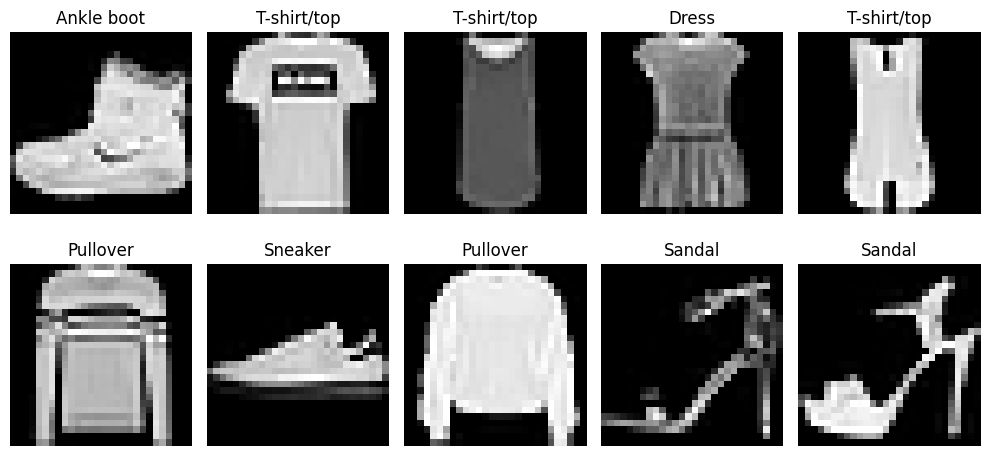

In [ ]:
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Normalisation  et encodage
X_train = X_train / 255.0
X_test = X_test / 255.0

y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)


Les pixels de MNIST sont entre 0 et 255.

En divisant par 255 :

- 0 devient 0.0
- 255 devient 1.0

Cela aide le réseau à apprendre plus facilement.

In [ ]:
print("Exemple de label original :", y_train[0])
print("Exemple de label one-hot  :", y_train_cat[0])

Exemple de label original : 9
Exemple de label one-hot  : [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


### Construction du MLP

In [ ]:
mlp_model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation="relu"),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

mlp_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#compilation
mlp_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
#Entrainement
history_mlp = mlp_model.fit(
    X_train,
    y_train_cat,
    validation_split=0.2,
    epochs=10,
    batch_size=128,
    verbose=1
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.7467 - loss: 0.7333 - val_accuracy: 0.8530 - val_loss: 0.4199
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8552 - loss: 0.3946 - val_accuracy: 0.8635 - val_loss: 0.3771
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8762 - loss: 0.3473 - val_accuracy: 0.8763 - val_loss: 0.3458
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8883 - loss: 0.3049 - val_accuracy: 0.8753 - val_loss: 0.3516
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8918 - loss: 0.2971 - val_accuracy: 0.8806 - val_loss: 0.3303
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9004 - loss: 0.2702 - val_accuracy: 0.8861 - val_loss: 0.3205
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9016 - loss: 0.2649 - val_accuracy: 0.8802 - val_loss: 0.3309
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9067 - loss: 0.2532 - val_accura

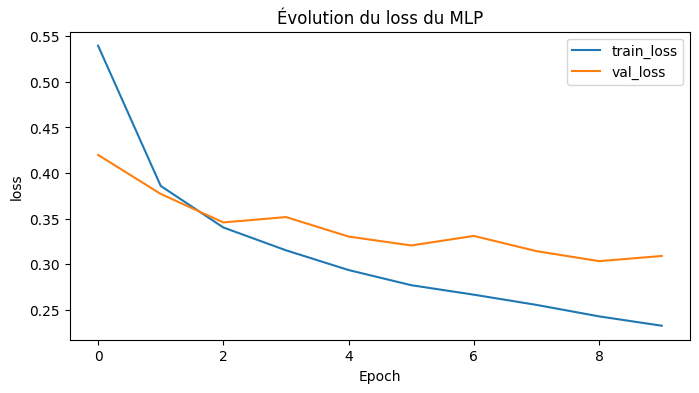

In [ ]:
# Visualisation des courbes d'apprentissages
plt.figure(figsize=(8, 4))
plt.plot(history_mlp.history["loss"], label="train_loss")
plt.plot(history_mlp.history["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("loss")
plt.title("Évolution du loss du MLP")
plt.legend()
plt.show()

In [ ]:
# Evaluation
mlp_test_loss, mlp_test_acc = mlp_model.evaluate(X_test, y_test_cat, verbose=0)
print("MLP Test Accuracy :", mlp_test_acc)

MLP Test Accuracy : 0.8813999891281128


In [ ]:
# prediction
y_pred_probs = mlp_model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_test, y_pred))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

           0       0.84      0.83      0.84      1000
           1       0.99      0.97      0.98      1000
           2       0.81      0.76      0.78      1000
           3       0.89      0.89      0.89      1000
           4       0.83      0.76      0.79      1000
           5       0.97      0.97      0.97      1000
           6       0.64      0.75      0.69      1000
           7       0.94      0.95      0.95      1000
           8       0.97      0.97      0.97      1000
           9       0.96      0.96      0.96      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



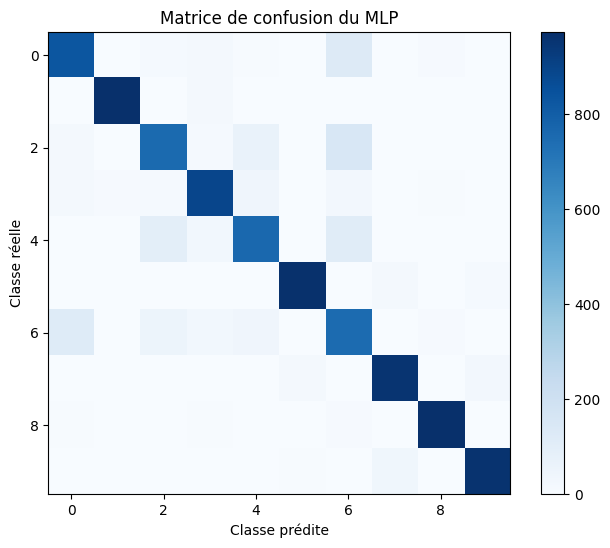

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap="Blues")
plt.title("Matrice de confusion du MLP")
plt.colorbar()
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.show()

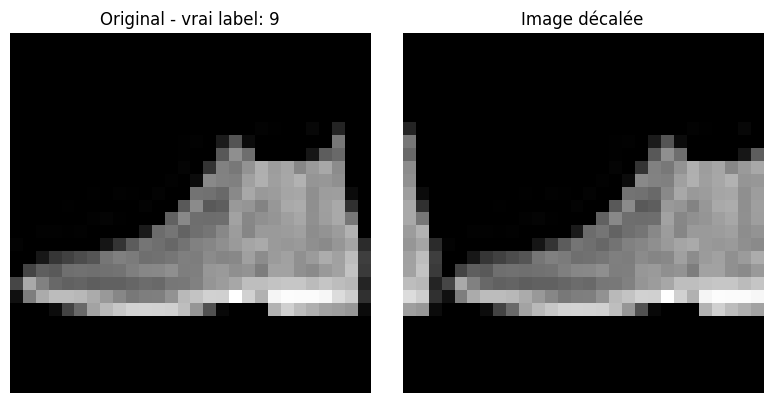

In [ ]:
# Afficher une image test et une version légèrement décalée
img = X_test[0]

shifted_img = np.roll(img, shift=3, axis=1)  # décalage horizontal

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title(f"Original - vrai label: {y_test[0]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(shifted_img, cmap="gray")
plt.title("Image décalée")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
pred_original = np.argmax(mlp_model.predict(img.reshape(1, 28, 28)), axis=1)[0]
pred_shifted = np.argmax(mlp_model.predict(shifted_img.reshape(1, 28, 28)), axis=1)[0]

print("Prédiction sur image originale :", pred_original)
print("Prédiction sur image décalée   :", pred_shifted)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
Prédiction sur image originale : 9
Prédiction sur image décalée   : 8
